<div align="left">
<img src="https://licensebuttons.net/l/by-nc-sa/3.0/88x31.png" align="right">
<p align="left"><b>Autor: Víctor Sánchez Anguix</b></p>
</div>
<img align="left" width="30%" src="https://www.upv.es/entidades/etsinf/wp-content/uploads/2024/06/logo_etsinf_valenciano_grisUPV.svg"/> <img width="30%" src="https://www.upv.es/perfiles/pas-pdi/imagenes/marca_UPV_principal_negro150.png" align="right"/>



# Optimization: Laboratory 2 - Assessing the empirical time complexity

In this laboratory we are going to study empirically the running complexity of linear programming algorithms. The objective of this practice is twofold. On the one hand, to continue familiarizing ourselves with the ORTools API, and on the other hand to observe how the time complexity of solving linear programming algorithms depends on both the number of variables involved and the number of constraints.  Let's start!

## Learning outcomes

* Describe the impact of the number of decision variables on the resolution time of a linear programming model
* Describe the impact of the number of constraints on the resolution time of a linear programming model
* Design empirical experiments to assess the impact of different hyperparameters on the resolution time of optimization models


# Preamble: Installing and importing the necessary libraries

As a first step to this laboratory. We are going to reinstall the ORTools optimization suite. This step is necessary whenever we are working with Google Colab, since every time we start a notebook a new cloud instance is assigned without pre-installed software. This step would not be necessary if you are working with a physical machine with its own Python installation. If you are working from Google Colab, run the following instruction to install ORTools.

In [ ]:
!pip install ortools

In the following code snippet we are going to import the Python modules that we will employ in this laboraroy. This step is necessary for all of us, so let's execute it.

In [1]:
from ortools.linear_solver import pywraplp
from numpy import average, std

# Measuring execution times in Python and ORTools


As you already know, execution time is a crucial factor in evaluating the complexity of algorithms and processes. This is especially true when our optimization model is integrated as a service with other tools and processes from the information system of our organization. It is always advisable that our optimization service is tested with a similar load to the one it will face once integrated into our information system. This information can help us to answers questions such as:
* In what average time am I able to obtain an optimal solution?   
* Is the response time acceptable in most cases for the rest of the processes and individuals that depend on it?
* Does my optimization model need a performance improvement?
* Are the problems addressed too large and therefore need to be decomposed into smaller subproblems?
* Can my optimization model operate in real time or should its use be relegated to batch processing?


These are just some of the questions that can be answered by temporarily evaluating our optimization model. Therefore, this evaluation is crucial as part of the integration in an information system. In this practice we are going to learn how to evaluate this time complexity, something that we will complement later when we compare the performance of different solvers.

The first thing we will learn is to measure the execution time of any code fragment in Python. For this we can use the *time* function available in the module of the same name. This function returns the time in seconds since January 1, 1970. In the following code fragment we measure the execution time of 100000 square root operations and print the elapsed time on the screen.

In [2]:
from time import time
import math
start_time = time()
for i in range(100000):
  math.sqrt(i)
total_time = time() - start_time
print(total_time)

0.011653423309326172


It should be noted that this code snippet measures elapsed time in seconds, this is not exactly the execution time for our code snippet when there are several processes running simultaneously and competing for CPU. However, for our test environments (e.g., Colab, personal machine, etc.) we can consider this to be the only process with high processing requirements as long as we are not doing anything else.

The above code snippet can be extrapolated to measure the execution time of virtually any code snippet, whether related to solving a linear programming problem or any other type of snippet. The ORTools linear programming API already has a method that gives us the time to solve a problem once it has been solved. Let's see an example in the following code snippet.

In [3]:
from random import randint

solver = pywraplp.Solver.CreateSolver('GLOP')
X1 = solver.NumVar(0, solver.infinity(), 'X1')
X2 = solver.NumVar(0, solver.infinity(), 'X2')
X3 = solver.NumVar(0, solver.infinity(), 'X3')
X4 = solver.NumVar(0, solver.infinity(), 'X4')


for i in range(1000):
  c = solver.Constraint(-solver.infinity(), randint(100, 1500))
  c.SetCoefficient(X1, randint(1,10))
  c.SetCoefficient(X2, randint(1,10))
  c.SetCoefficient(X3, randint(1,10))
  c.SetCoefficient(X4, randint(1,10))

o = solver.Objective()
o.SetCoefficient(X1, 3.1)
o.SetCoefficient(X2, 1.3)
o.SetCoefficient(X3, 2)
o.SetCoefficient(X4, 1)
o.SetMaximization()

type_result = solver.Solve()
print("Elapsed time since solver instance creation is", solver.wall_time())

Elapsed time since solver instance creation is 21


In the above code snippet we have generated a linear programming problem with four decision variables (X1, X2, X3, X4) and 1000 random constraints of the type:

$ a_1 X_1 + a_2 X_2 + a_3 X_3 + a_4 X_4 \leq b $

where $a_i$ are randomly generated integer coefficients between 1 and 10, and $b$ is also a randomly generated integer between 100 and 1500. The code fragment in charge of creating the constraints is the following:

```python
for i in range(1000):
  c = solver.Constraint(-solver.infinity(), randint(100, 1500))
  c.SetCoefficient(X1, randint(1,10))
  c.SetCoefficient(X2, randint(1,10))
  c.SetCoefficient(X3, randint(1,10))
  c.SetCoefficient(X4, randint(1,10))
```

The maximization objective is then created:

$ max;Z = 3.1 X_1 + 1.3 X_2 + 2 X_3 + X_4 $

Notice that once the linear programming model is solved, we can use the *WallTime* method on the solver to obtain **the time elapsed from the creation of the Solver object** to the call to *WallTime*. This makes it much easier for us to evaluate the time evaluation of models solved with ORTools.

**NOTE:** Note how the time returned in this case is the elapsed in milliseconds and not the elapsed seconds as in the case of *time*.

# Task 1: Studying the impact of the number of variables on the temporal evaluation of the model

In this task, we will empirically study the impact of the number of variables in a model on the time to solve a linear programming problem. To do so, we will create different instances of linear programming problems with similar characteristics (e.g., type of constraints, type of objective, proportion of constraints, etc.) but different number of variables.

First of all, let's look at a function already provided by this notebook to create a random problem instance given a set of input characteristics.

In [4]:
def generate_random_lp_problem(num_variables, num_constraints, min_rhs=50,
                               max_rhs=200, prob_constraint=0.5,
                               min_coefficient=1, max_coefficient=50,
                               solver_type='GLOP'):
  from random import random, randint, shuffle
  solver = pywraplp.Solver.CreateSolver( solver_type )
  variables = [ solver.NumVar(0, solver.infinity(), "X"+str(i)) for i in range(num_variables)  ]
  constraints = []
  for i in range(num_constraints):
    rhs = randint(min_rhs, max_rhs)
    c = solver.Constraint(-solver.infinity(), rhs)
    shuffle(variables)
    first_time = True
    for v in variables :
      if first_time or random()<prob_constraint:
        c.SetCoefficient(v, randint(min_coefficient, max_coefficient))
        first_time = False
    constraints.append(c)

  o = solver.Objective()
  for v in variables :
    o.SetCoefficient(v, randint(min_coefficient, max_coefficient))
  o.SetMaximization()

  return (variables, constraints, o, solver)

The above function creates a randomized linear programming maximization problem with constraints of type $\leq$. The generated problem can be configured with the input parameters of the function. Some of these parameters are mandatory at the time the function is called, while others are optional and, if not provided, they will a default value. Let's see what each of these parameters are.


| Name | Type | Description |
| --- | --- | --- |
| *num_variables* |  required  | Number of decision variables | |
| *num_constraints*| required  | Number of constraints |
|  *min_rhs* | optional |  Minimum constant for the inequality ($b_i$)  |
|  *max_rhs* | optional |  Maximum constant for the inequality ($b_i$)  |
|  *prob_constraint* | optional | Probability that a decision variable participates in a constraint   |
| *min_coefficient* | optional | Minimum coefficient ($a_i$) for the decision variables |
| *max_coefficient* | optional | Maximum coefficient ($a_i$) for the decision variables |
| *solver_type* | optional |  Type of solver to use  |

Although it is not necessary to understand 100% the code provided, it would be a good idea to make the effort to understand how the problems are generated in order to become proficient with both Python and ORTools. The function returns a tuple with a list of variables created, a list of constraints created, the objective function created, and the solver type object created.

You will not have to create this function, but you will have to use it throughout the laboratory, so let's see some examples of its use.






In [5]:
(variables, constraints, o, solver) = generate_random_lp_problem(10, 100)
result_type = solver.Solve()
if result_type == solver.OPTIMAL :
  print("Optimal solution found!!")
elif result_type == solver.UNBOUNDED :
  print("Unbounded solution!")
elif result_type == solver.INFEASIBLE :
  print("The problem is infaseible")

Optimal solution found!!


In the above example we have created a problem with 10 decision variables and 100 constraints. After that, we have solved the problem. The rest of the optional parameters have been left at their default value (i.e., defined in the function header). In the example used below, we generate a problem with 20 decision variables and 50 constraints. In addition, we changed the value for the optional *max_coefficient* parameter to 25.

In [6]:
(variables, constraints, o, solver) = generate_random_lp_problem(20, 50, max_coefficient=25)
result_type = solver.Solve()
if result_type == solver.OPTIMAL :
  print("Optimal solution found!!")
elif result_type == solver.UNBOUNDED :
  print("Unbounded solution!")
elif result_type == solver.INFEASIBLE :
  print("The problem is infaseible")

Optimal solution found!!


Recall now that our task is to empirically evaluate the impact of the number of variables in solving linear programming models. For this you will have to take the following considerations:

* We will start with a number of variables equal to 100 and in steps of 100 we will increase up to 1000 (included).
* The number of constraints will be kept constant at 100.
* For each number of variables, we will generate a total of 30 different problems.
* We solve each of the problems, store their time. Finally we calculate the mean and standard deviation for that number of variables. We store both the mean and standard deviation in a different list.

In [ ]:
# Your code here
variable_counts = list(range(100, 1001, 100))
mean_times = []
std_times = []
num_constraints = 100
num_problems = 30

for num_variables in variable_counts:
    current_times = []
    
    for _ in range(num_problems):
        # Generate the random problem using the provided helper function
        variables, constraints, o, solver = generate_random_lp_problem(num_variables, num_constraints)
        
        # Solve the model
        solver.Solve()
        
        # Store the elapsed time in milliseconds from the creation of the solver
        current_times.append(solver.wall_time())
        
    # Calculate and store the mean and standard deviation for the current variable count
    mean_times.append(average(current_times))
    std_times.append(std(current_times))

Variable Counts: [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]
Mean Times (ms): [np.float64(4.3), np.float64(9.4), np.float64(12.166666666666666), np.float64(17.7), np.float64(21.033333333333335), np.float64(26.066666666666666), np.float64(30.2), np.float64(34.7), np.float64(40.0), np.float64(45.666666666666664)]
Standard Deviations (ms): [np.float64(0.6403124237432849), np.float64(3.1155523854794462), np.float64(0.45338235029118146), np.float64(1.7156145643277028), np.float64(0.9122621455602673), np.float64(0.9637888196533974), np.float64(0.8717797887081347), np.float64(0.862167810425171), np.float64(1.1254628677422756), np.float64(2.022100118413747)]


Once the data has been collected, we are going to represent in in a graph to interpret the results more easily. In the following code fragment we have defined two lists (one for the X-axis, and one for the Y-axis) and plotted them on a graph with their respective errors. To do this, we use Matplotlib, a visualization library implemented in Python.

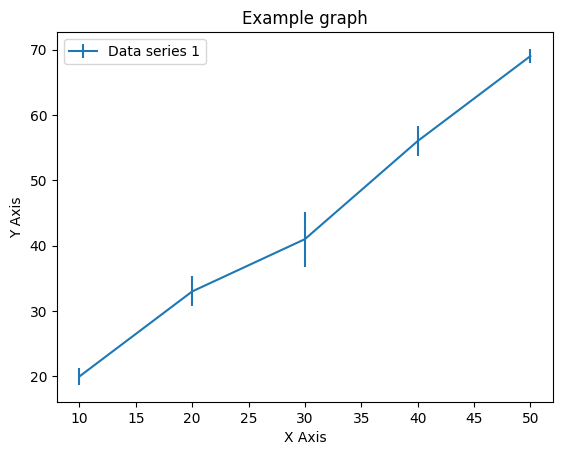

In [8]:
import matplotlib.pyplot as plt

x = [10, 20, 30, 40, 50]
y = [20, 33, 41, 56, 69]
errors = [1.3, 2.3, 4.2, 2.3, 1.1]

fig= plt.errorbar(x,y, yerr=errors)
plt.xlabel("X Axis")
plt.ylabel("Y Axis")
plt.title("Example graph")
plt.legend( ["Data series 1"] )


In the example above we have created an error bar chart based on the data in the x and y lists, and their corresponding errors. The plot has a label for the x-axis called "X axis" and a label for the y-axis called "Y axis". In addition, the plot also has a general title (top) and a legend.

Now, represent the data collected in the experiment with the numbers of variables on the x-axis, the mean times on the y-axis, and the standard deviations as errors.

Text(0.5, 1.0, 'Graph task 1')

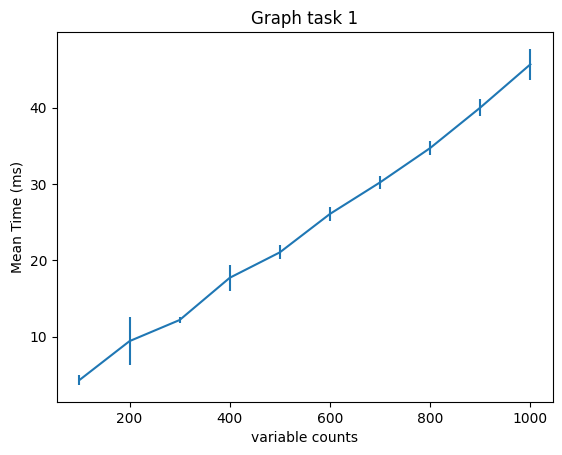

In [10]:
# Your code here
x = variable_counts
y = mean_times
errors = std_times

fig= plt.errorbar(x,y, yerr=errors)
plt.xlabel("variable counts")
plt.ylabel("Mean Time (ms)")
plt.title("Graph task 1")

Now try to answer the following questions:


* Does the number of variables have an impact on the execution time for  analyzed models?

    Sí, a mayor número de variables mayor es el tiempo de ejecución.
* For the type of problems generated, and keeping the number of constraints fixed, what kind of relationship, on average, seems to exist between the number of variables and the time complexity for the algorithm studied?

    Existe una relación lineal y directamente proporcional entre el número de variables y el tiempo medio de ejecución. A medida que el número de variables aumenta de manera constante en el eje X, el tiempo medio necesario para resolver el problema en milisegundos también crece de forma proporcional y lineal a lo largo del eje Y.



# Task 2: Studying the impact of the number of constraints on the temporal evaluation of the model

Now we will repeat the process with the number of constraints. For this you will have to take the following considerations:

* We will start with a number of constraints equal to 100 and in steps of 100 we will increase up to 1000 (included).
* The number of variables will be kept constant at 100.
* For each number of constraints, we will generate a total of 30 different problems.
* We solve each of the problems, store their time. Finally we calculate the mean and standard deviation for that number of constraints. We store both the mean and standard deviation in a different list.

In [ ]:
#Your code here
variable_counts = list(range(100, 1001, 100))
mean_times = []
std_times = []
num_constraints = 100
num_problems = 30

for num_constraints in list(range(100, 1001, 100)):
    current_times = []
    
    for _ in range(num_problems):
        # Generate the random problem using the provided helper function
        variables, constraints, o, solver = generate_random_lp_problem(num_variables, num_constraints)
        
        # Solve the model
        solver.Solve()
        
        # Store the elapsed time in milliseconds from the creation of the solver
        current_times.append(solver.wall_time())
        
    # Calculate and store the mean and standard deviation for the current constraint count
    mean_times.append(average(current_times))
    std_times.append(std(current_times))

Now plot the data obtained from the experiment on a graph, just as we did in the previous experiment.

Text(0.5, 1.0, 'Graph task 2')

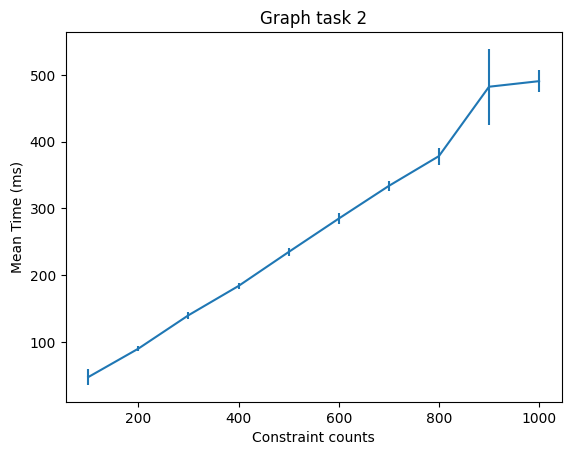

In [16]:
# Your code here
x = list(range(100, 1001, 100))
y = mean_times
errors = std_times

fig= plt.errorbar(x,y, yerr=errors)
plt.xlabel("Constraint counts")
plt.ylabel("Mean Time (ms)")
plt.title("Graph task 2")

Now try to answer the following questions:


* Does the number of constraints have an impact on the execution time for the analyzed models?

    Sí, el número de restricciones tiene un impacto directo y significativo en el tiempo de ejecución. A medida que aumentan las restricciones (eje X), el tiempo medio necesario para resolver el problema (eje Y) también se incrementa.
* For the type of problems generated, and keeping the number of variables constant, what kind of relationship, on average, seems to exist between the number of constraints and the time complexity for the algorithm studied?

    Manteniendo constante el número de variables, parece existir una relación lineal y directamente proporcional entre el número de restricciones y el tiempo medio de ejecución.

# Task 3: Studying the combined impact of the number of variables and the number of constraints on the temporal evaluation of the model

We have studied the isolated impact of the number of variables and the number of constraints in solving linear programming problems. For these experiments, we kept either the number of constraints or the number of experiments constant. However, in practice, the two usually go hand in hand, since the more variables, the more constraints we tend to have. Therefore, it is also interesting to study their combined impact.

Let us suppose now that we are studying a type of problem where, given a number of variables, we have approximately half as many constraints as variables. For this type of problem, we are going to study the combined impact of the number of variables and constraints on the execution time.

Now design an experiment following the following guidelines:

* We will start with a number of variables equal to 100 and in steps of 100 we will increase up to 1000 (included).
* The number of constraints will be half the number of variables.
* For each number of variables, we will generate a total of 30 different problems.
* We solve each of the problems, and store their time. Finally we calculate the mean and standard deviation for that number of variables. We store both the mean and standard deviation in a different list.

In [17]:
#Your code here
variable_counts = list(range(100, 1001, 100))
mean_times = []
std_times = []
num_problems = 30

for num_variables in variable_counts:
    current_times = []
    num_constraints = num_variables // 2 # Set the number of constraints to half the number of variables
    
    for _ in range(num_problems):
        # Generate the random problem using the provided helper function
        variables, constraints, o, solver = generate_random_lp_problem(num_variables, num_constraints)
        
        # Solve the model
        solver.Solve()
        
        # Store the elapsed time in milliseconds from the creation of the solver
        current_times.append(solver.wall_time())
        
    # Calculate and store the mean and standard deviation for the current variable count
    mean_times.append(average(current_times))
    std_times.append(std(current_times))

Once this experiment has been carried out, represent it graphically to analyze its impact.

Text(0.5, 1.0, 'Graph task 3')

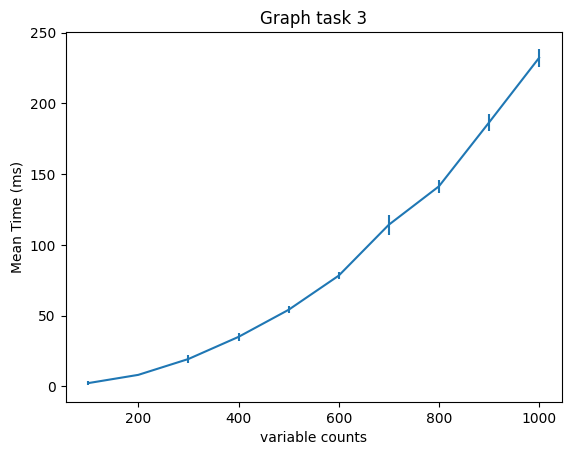

In [19]:
#Your code here
x = variable_counts
y = mean_times
errors = std_times

fig= plt.errorbar(x,y, yerr=errors)
plt.xlabel("variable counts")
plt.ylabel("Mean Time (ms)")
plt.title("Graph task 3")

Now try to answer the following questions:


* What kind of relationship, on average, do you think exists when we increase the number of variables and constraints with respect to the execution time?

# Configuring the solver in ORTools

ORTools allows us to configure some specific parameters of the underlying solver. To create a parameter configuration for a linear or integer programming solver, we create an object of the class *MPSolverParameters* as we can see in the following example.

In [20]:
parameters = pywraplp.MPSolverParameters()

Once the object is created, we can change some of the solver parameters using the *SetIntegerParam* and *SetDoubleParam* methods, using one or the other depending on whether the parameter to be set is of type integer or double. In the following list we find a list of the parameters that we can currently set with this method.

|     Parameter    |  Type  |                                                                  Values                                                                 |
|:----------------:|:------:|:----------------------------------------------------------------------------------------------------------------------------------------:|
| *RELATIVE_MIP_GAP* |  Duoble |                                                                     -                                                                    |
| *PRIMAL_TOLERANCE* |  Double |                                                                     -                                                                    |
| *DUAL_TOLERANCE*   |  Double |                                                                     -                                                                    |
| *INCREMENTALITY*   | Integer | *INCREMENTALITY_OFF*<br>*INCREMENTALITY_ON*<br><br>If previous results should<br>be used to solve the current problem                                 |
| *PRESOLVE*         | Integer | *PRESOLVE_OFF*<br>*PRESOLVE_ON*<br><br>Sets if preprocessing should be carried out<br>to reduce redundant constraints and variables    |
| *SCALING*          | Integer | *SCALING_OFF*<br>*SCALING_ON*<br><br>Adjust coefficients to <br>improve the numerical stability and iterations |
| *LP_ALGORITHM*     | Entero | *DUAL* (Dual Simplex)<br>*PRIMAL* (Primal Simplex)<br>*BARRIER* (Interior Point Method)                                                     |

In principle, many of the parameters used by ORTools and GLOP are already optimized to work well for most cases, but we can adjust them manually if necessary. For example, in the following lines of code we select the PRIMAL algorithm as the resolution algorithm.

In [21]:
parameters.SetIntegerParam(parameters.LP_ALGORITHM, parameters.PRIMAL)

If we would like this configuration to be used in the solver, we must provide it at the time of solving the problem. That is, at the moment we call the *Solve* method.

In [22]:
result_type = solver.Solve(parameters)

# Task 4: Comparing two algorithms/solvers

Now we are going to study empirically how to compare the execution time of two solvers or algorithms. We have provided a function that copies a linear problem, so that we can compare both algorithms fairly. This function receives a list of variables, constraints, and objectives, and returns a list with the new variables, constraints, and objective, plus the solver object to solve the problem.

You don't need to understand 100% of the code below, but again we recommend that you take a look at it to become more familiar with the ORTools API.

In [23]:
def copy_problem(variables, constraints, objective, solver_type="GLOP"):
  solver = pywraplp.Solver.CreateSolver(solver_type)
  new_variables = [ solver.NumVar(variables[i].Lb(), variables[i].Ub(), "v"+str(i)) for i in range(len(variables)) ]
  new_constraints = []
  for i in range(len(constraints)) :
    lb = constraints[i].Lb()
    ub = constraints[i].Ub()
    nc = solver.Constraint(lb, ub)
    for j in range(len(variables)):
      coefficient = constraints[i].GetCoefficient(variables[j])
      nc.SetCoefficient(new_variables[j], coefficient)
    new_constraints.append(nc)

  new_objective = solver.Objective()
  if objective.maximization():
    new_objective.SetMaximization()
  else :
    new_objective.SetMinimization()
  for i in range(len(variables)):
    coefficient = objective.GetCoefficient(variables[i])
    new_objective.SetCoefficient(new_variables[i], coefficient)
  return (new_variables, new_constraints, new_objective, solver)

With these functions we are going to create a new experiment in which we analyze the benefits of solving the dual problem instead of the primal problem. We will focus on simulating scenarios where the number of constraints is greater than the number of variables, since this is a scenario where the dual problem can be solved faster than the primal problem. With this in mind, we will design an experiment with the following characteristics:
* We will test problems with variables from 500 to 3500 in increments of 500.
* The number of constraints will always be kept at half the number of variables.
* For each possible number of constraints, we will generate a total of 10 possible problems.
* The first solver will be configured with the *PRIMAL* algorithm and the second solver will be configured with the *DUAL* algorithm. The *INCREMENTALITY* will be disabled.
* We will solve the first model and store both the average run time and the standard deviation for each number of variables checked.
* We will do the same with the model copied and solved with the dual algorithm.

In [30]:
#Your code here
variable_counts = list(range(500, 3501, 500))
mean_times = []
mean_times_copy = []
std_times = []
std_times_copy = []
num_problems = 10

for num_variables in variable_counts:
    current_times = []
    copy_current_times = []
    num_constraints = num_variables // 2 # Set the number of constraints to half the number of variables
    
    for _ in range(num_problems):

        # Generate the random problem using the provided helper function
        variables, constraints, o, solver = generate_random_lp_problem(num_variables, num_constraints)
        # Copy the problem to a new solver instance
        variables_copy, constraints_copy, o_copy, solver_copy = copy_problem(variables, constraints, o)


        parameters = pywraplp.MPSolverParameters()
        # Set the solver parameters to use the primal simplex algorithm 
        parameters.SetIntegerParam(parameters.LP_ALGORITHM, parameters.PRIMAL)
        parameters.SetIntegerParam(parameters.INCREMENTALITY, parameters.INCREMENTALITY_OFF)
        # Medir el tiempo de ejecución del solver 1 (Primal)
        start_time_primal = time()
        solver.Solve(parameters)
        end_time_primal = time()


        parameters_copy = pywraplp.MPSolverParameters()
        # Set the solver parameters to use the dual simplex algorithm 
        parameters_copy.SetIntegerParam(parameters_copy.LP_ALGORITHM, parameters_copy.DUAL)
        parameters_copy.SetIntegerParam(parameters_copy.INCREMENTALITY, parameters_copy.INCREMENTALITY_OFF)
        # Medir el tiempo de ejecución del solver 2 (Dual)
        start_time_dual = time()
        solver_copy.Solve(parameters_copy)
        end_time_dual = time()

        # Calcular el tiempo transcurrido en milisegundos y guardarlo
        execution_time_primal_ms = (end_time_primal - start_time_primal) * 1000
        current_times.append(execution_time_primal_ms)
        # Calcular el tiempo transcurrido en milisegundos y guardarlo
        execution_time_dual_ms = (end_time_dual - start_time_dual) * 1000
        copy_current_times.append(execution_time_dual_ms)
        
    # Calculate and store the mean and standard deviation for the current variable count
    mean_times.append(average(current_times))
    mean_times_copy.append(average(copy_current_times))
    std_times.append(std(current_times))
    std_times_copy.append(std(copy_current_times))

Now that we have collected the experiment data, we are going to plot it graphically with Matplotlib. To do this, we will plot both sets of data on the same graph. In the following code snippet we have an example of how we can perform this task with Matplotlib.

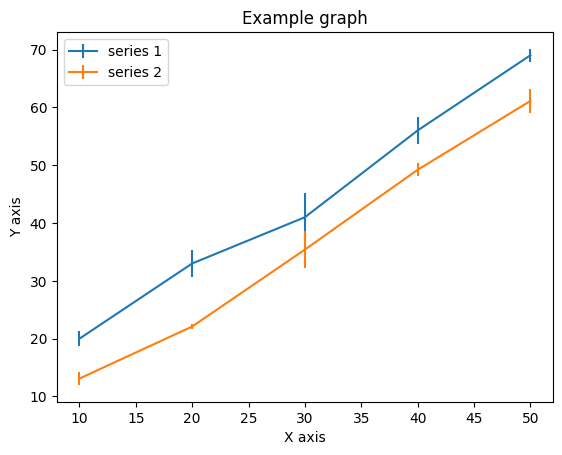

In [25]:
from matplotlib import pyplot as plt
x = [10, 20, 30, 40, 50]
x2 = [10, 20, 30, 40, 50]
y = [20, 33, 41, 56, 69]
y2 = [13.1, 22.1, 35.4, 49.2, 61.1]
errors = [1.3, 2.3, 4.2, 2.3, 1.1]
errors2 = [1.1, 0.4, 3.2, 1.1, 2.0]

fig= plt.errorbar(x,y, yerr=errors)
plt.xlabel("X axis")
plt.ylabel("Y axis")
plt.title("Example graph")
plt.subplot()
plt.errorbar(x2,y2, yerr=errors2)
plt.legend( ["series 1", "series 2"] )

Now implement your code to compare the resolutions of the dual and primal algorithm.

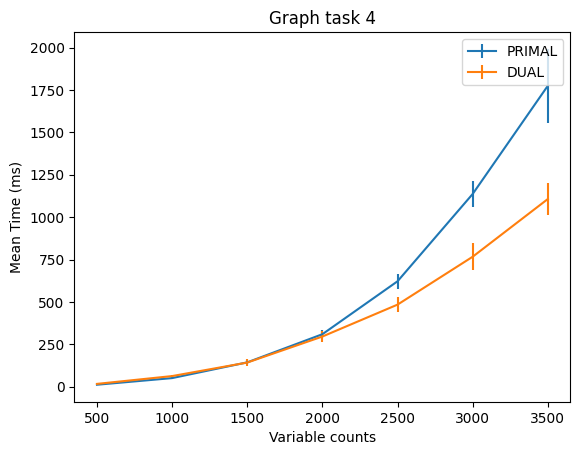

In [31]:
#Your code here
from matplotlib import pyplot as plt
x = variable_counts
x2 = variable_counts
y = mean_times
y2 = mean_times_copy
errors = std_times
errors2 = std_times_copy

fig= plt.errorbar(x,y, yerr=errors)
plt.xlabel("Variable counts")
plt.ylabel("Mean Time (ms)")
plt.title("Graph task 4")
plt.subplot()
plt.errorbar(x2,y2, yerr=errors2)
plt.legend( ["PRIMAL", "DUAL"] )

Based on the experiment carried out, which algorithm was the most efficient to solve and why?
Primal se observa en la gráfica.